# HealthyAir - Data Cleaning Notebook
Run these notebooks in order: exploration → cleaning → feature engineering, keeping the raw files unchanged.

## Data cleaning
This notebook creates a cleaned copy, it does not overwrite the raw data. A fixed seed makes resampling repeatable.

In [1]:
# Import Libraries
import sys
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import statsmodels
import scipy
import os
import gcsfs
import warnings
from scipy import stats

# Confirm location
print("Location:", sys.executable)

SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option("display.max_columns", 30)
#pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("statsmodels:", statsmodels.__version__)

Location: /home/chloekc/datahandling/healthyair/.venv/bin/python
Python: 3.12.3
NumPy: 2.5.3
pandas: 3.0.6
SciPy: 1.18.1
Matplotlib: 3.11.1
Seaborn: 0.13.2
statsmodels: 0.15.0


## 1. Load and validate data

In [2]:
# Load data from Google Cloud Storage
GCS_PROJECT_ID = "healthy_air_analysis"
GCS_BUCKET = "uci_air_quality_20119102"
GCS_FILE = "gs://uci_air_quality_20119102/data_raw/AirQualityUCI.csv"
df = pd.read_csv(GCS_FILE)

# Data contract
required = {"Date", "Time", "CO(GT)", "PT08.S1(CO)", "NMHC(GT)", "C6H6(GT)",
            "PT08.S2(NMHC)", "NOx(GT)", "PT08.S3(NOx)", "NO2(GT)", "PT08.S4(NO2)", "PT08.S5(O3)", "T", "RH", "AH"}
assert required.issubset(df.columns)
#assert set(df["Quality"].unique()).issubset({0, 1, 3})
print("Initial data-contract checks passed.")

print("Dataset path:", GCS_BUCKET)
print(f"Rows: {df.shape[0]:,}; columns: {df.shape[1]}")
display(df.head())

Initial data-contract checks passed.
Dataset path: uci_air_quality_20119102
Rows: 9,471; columns: 17


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,3/10/2004,18:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,3/10/2004,19:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,3/10/2004,20:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,3/10/2004,21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,3/10/2004,22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN


## 2. Timestamp Analysis

In [ ]:
# Preserve the original dataset
df_clean = df.copy()

# Combine Date and Time using the correct format
df_clean["Datetime"] = pd.to_datetime(
    df_clean["Date"].astype("string").str.strip() + " " +
    df_clean["Time"].astype("string").str.strip(),
    format="%m/%d/%Y %H:%M:%S",
    errors="coerce"
)

# Check conversion
print("Total rows:", len(df_clean))
print("Valid timestamps:", df_clean["Datetime"].notna().sum())
print("Missing timestamps:", df_clean["Datetime"].isna().sum())

print("\nFirst timestamp:", df_clean["Datetime"].min())
print("Last timestamp:", df_clean["Datetime"].max())

Total rows: 9471
Valid timestamps: 9357
Missing timestamps: 114

First timestamp: 2004-03-10 18:00:00
Last timestamp: 2005-04-04 14:00:00


In [ ]:
missing_dates = df_clean[df_clean["Datetime"].isna()]

print("Rows with missing timestamps:", len(missing_dates))

display(missing_dates.head(10))

print("\nNon-empty values in missing timestamp rows:")
print(missing_dates.notna().sum())

Rows with missing timestamps: 0


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16,Datetime



Non-empty values in missing timestamp rows:
Date             0
Time             0
CO(GT)           0
PT08.S1(CO)      0
NMHC(GT)         0
C6H6(GT)         0
PT08.S2(NMHC)    0
NOx(GT)          0
PT08.S3(NOx)     0
NO2(GT)          0
PT08.S4(NO2)     0
PT08.S5(O3)      0
T                0
RH               0
AH               0
Unnamed: 15      0
Unnamed: 16      0
Datetime         0
dtype: int64


In [ ]:
# Remove rows without a valid timestamp
df_clean = df_clean.dropna(subset=["Datetime"]).copy()

# Sort chronologically
df_clean = df_clean.sort_values("Datetime").reset_index(drop=True)

print("Cleaned dataset shape:", df_clean.shape)
print("First observation:", df_clean["Datetime"].min())
print("Last observation:", df_clean["Datetime"].max())

# Calculate time differences between observations
df_clean["Time_Difference"] = df_clean["Datetime"].diff()

# Check the intervals
print(df_clean["Time_Difference"].value_counts().head(10))

# Identify gaps larger than one hour
gaps = df_clean[df_clean["Time_Difference"] > pd.Timedelta(hours=1)]

print("\nGaps larger than one hour:", len(gaps))
display(gaps[["Datetime", "Time_Difference"]].head(20))

Cleaned dataset shape: (9357, 18)
First observation: 2004-03-10 18:00:00
Last observation: 2005-04-04 14:00:00

Time intervals:
Datetime
0 days 01:00:00    9356
Name: count, dtype: int64


## 3. Check duplicates, gaps and ranges
Because every observation is exactly one hour apart, target for next hour prediction is viable.

In [ ]:
print("Date range:")
print(df_clean["Datetime"].min(), "to", df_clean["Datetime"].max())
display(df_clean[["Datetime", "Date", "Time"]].head(10))

Date range:
2004-03-10 18:00:00 to 2005-04-04 14:00:00


,Datetime,Date,Time
0,2004-03-10 18:00:00,3/10/2004,18:00:00
1,2004-03-10 19:00:00,3/10/2004,19:00:00
2,2004-03-10 20:00:00,3/10/2004,20:00:00
3,2004-03-10 21:00:00,3/10/2004,21:00:00
4,2004-03-10 22:00:00,3/10/2004,22:00:00
5,2004-03-10 23:00:00,3/10/2004,23:00:00
6,2004-03-11 00:00:00,3/11/2004,0:00:00
7,2004-03-11 01:00:00,3/11/2004,1:00:00
8,2004-03-11 02:00:00,3/11/2004,2:00:00
9,2004-03-11 03:00:00,3/11/2004,3:00:00


In [ ]:
print(df_clean[["Unnamed: 15", "Unnamed: 16"]].notna().sum())

Unnamed: 15    0
Unnamed: 16    0
dtype: int64


In [ ]:
df_clean = df_clean.drop(columns=["Unnamed: 15", "Unnamed: 16"])

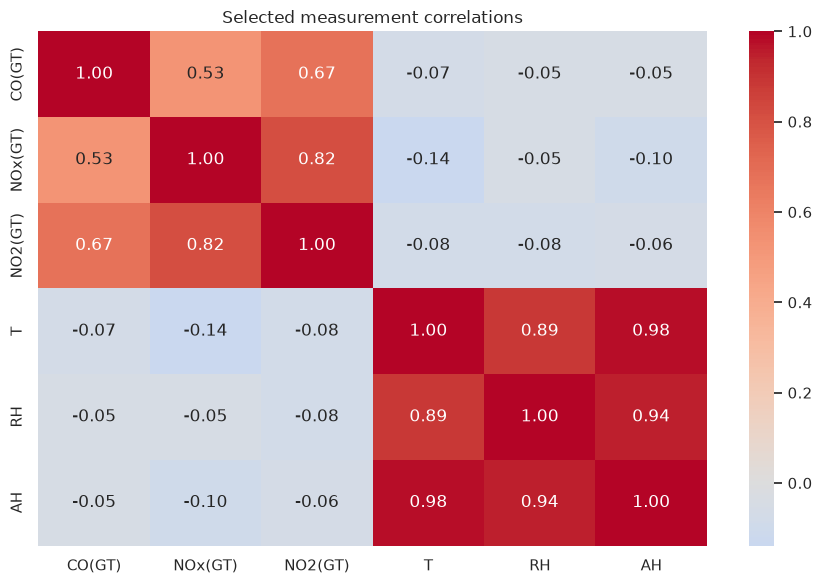

In [ ]:
# Relationships
selected = [c for c in ["CO(GT)", "NOx(GT)", "NO2(GT)", "T", "RH", "AH"] if c in df_clean.columns]
if len(selected) > 1:
    plt.figure(figsize=(9, 6))
    sns.heatmap(df_clean[selected].corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f")
    plt.title("Selected measurement correlations")
    plt.tight_layout()
    plt.show()

if "timestamp" in df_clean and "NO2(GT)" in df_clean:
    p = df_clean[["timestamp", "NO2(GT)"]].dropna().sort_values("timestamp")
    plt.figure(figsize=(14, 4))
    plt.plot(p.timestamp, p["NO2(GT)"], linewidth=.6)
    plt.xlabel("Time"); plt.ylabel("NO2(GT)")
    plt.title("Hourly NO2 measurements")
    plt.tight_layout(); plt.show()

In [ ]:
print("Duplicate timestamps:", df_clean["Datetime"].duplicated().sum())

Duplicate timestamps: 0


In [ ]:
print("Final rows:", len(df_clean))
print("Final columns:", len(df_clean.columns))

Final rows: 9357
Final columns: 16


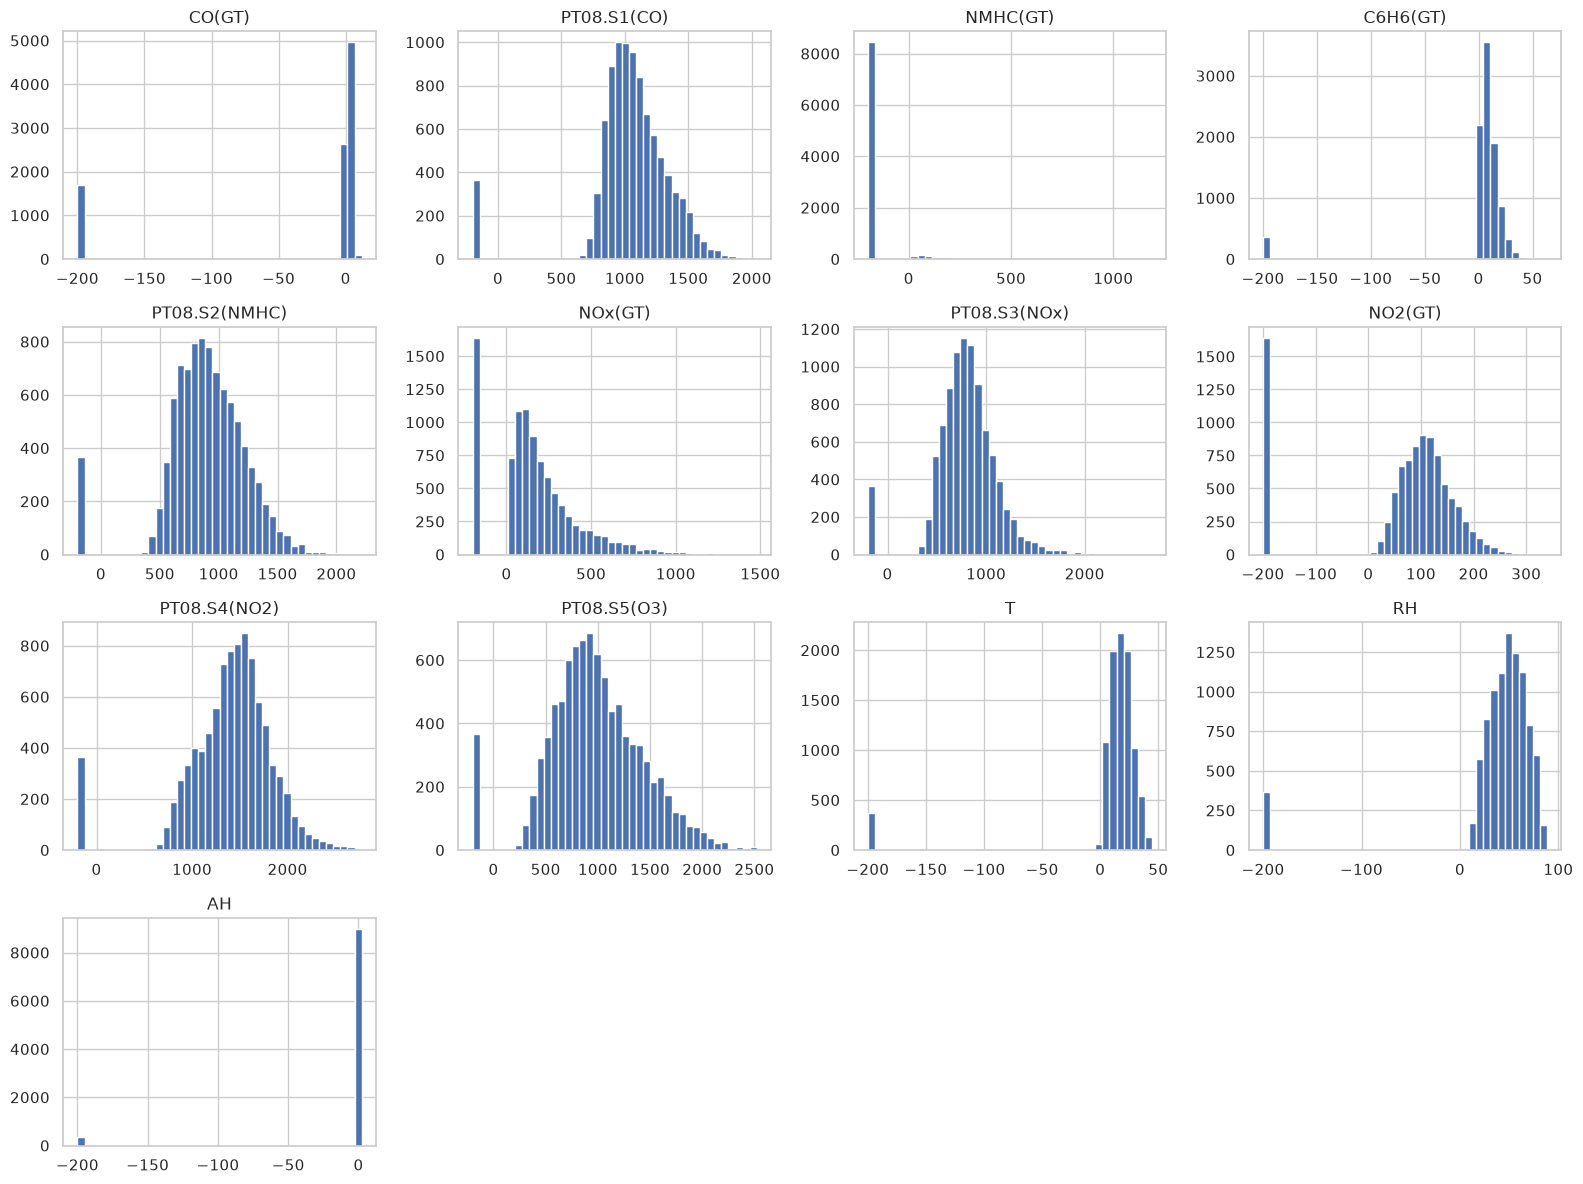

In [ ]:
# Measurement Distributions
numeric = df_clean.select_dtypes(include="number")
numeric.hist(figsize=(16, 12), bins=40)
plt.tight_layout()
plt.show()

In [ ]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 9357 entries, 0 to 9356
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           9357 non-null   str           
 1   Time           9357 non-null   str           
 2   CO(GT)         9357 non-null   float64       
 3   PT08.S1(CO)    9357 non-null   float64       
 4   NMHC(GT)       9357 non-null   float64       
 5   C6H6(GT)       9357 non-null   float64       
 6   PT08.S2(NMHC)  9357 non-null   float64       
 7   NOx(GT)        9357 non-null   float64       
 8   PT08.S3(NOx)   9357 non-null   float64       
 9   NO2(GT)        9357 non-null   float64       
 10  PT08.S4(NO2)   9357 non-null   float64       
 11  PT08.S5(O3)    9357 non-null   float64       
 12  T              9357 non-null   float64       
 13  RH             9357 non-null   float64       
 14  AH             9357 non-null   float64       
 15  Datetime       9357 non-null   d

In [18]:
df.describe()

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Datetime
count,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357
mean,-34.207524,1048.990061,-159.090093,1.865683,894.595276,168.616971,794.990168,58.148873,1391.479641,975.072032,9.778305,39.485380,-6.837604,2004-09-21 16:00:00
min,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,2004-03-10 18:00:00
25%,0.600000,921.000000,-200.000000,4.000000,711.000000,50.000000,637.000000,53.000000,1185.000000,700.000000,10.900000,34.100000,0.692300,2004-06-16 05:00:00
50%,1.500000,1053.000000,-200.000000,7.900000,895.000000,141.000000,794.000000,96.000000,1446.000000,942.000000,17.200000,48.600000,0.976800,2004-09-21 16:00:00
75%,2.600000,1221.000000,-200.000000,13.600000,1105.000000,284.000000,960.000000,133.000000,1662.000000,1255.000000,24.100000,61.900000,1.296200,2004-12-28 03:00:00
max,11.900000,2040.000000,1189.000000,63.700000,2214.000000,1479.000000,2683.000000,340.000000,2775.000000,2523.000000,44.600000,88.700000,2.231000,2005-04-04 14:00:00
std,77.657170,329.832710,139.789093,41.380206,342.333252,257.433866,321.993552,126.940455,467.210125,456.938184,43.203623,51.216145,38.976670,NaN


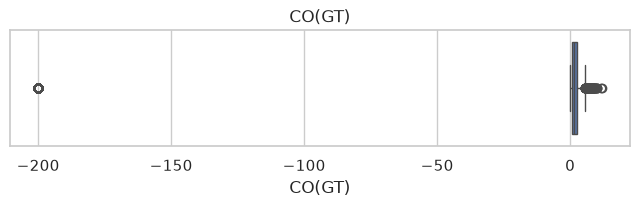

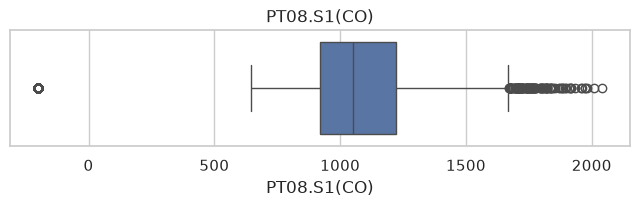

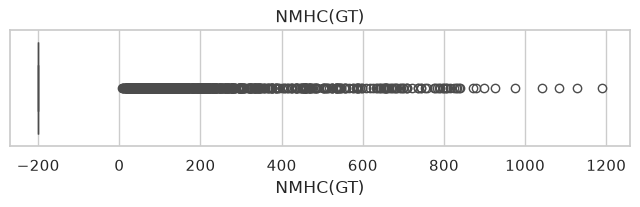

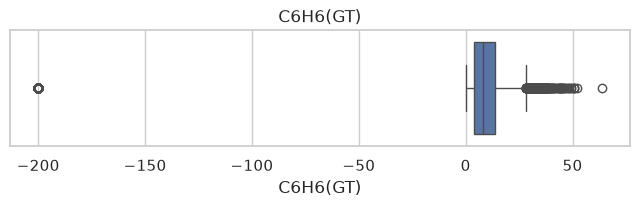

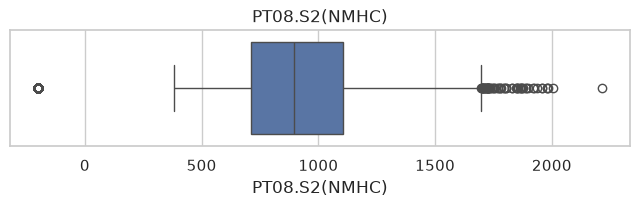

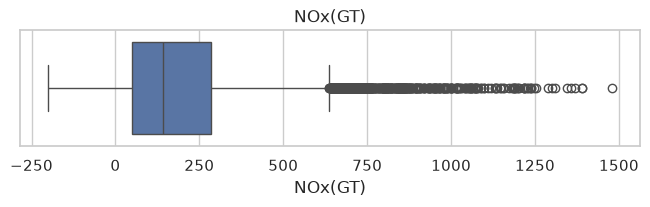

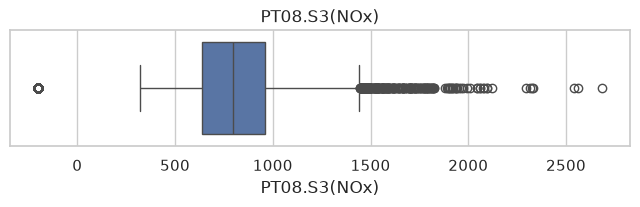

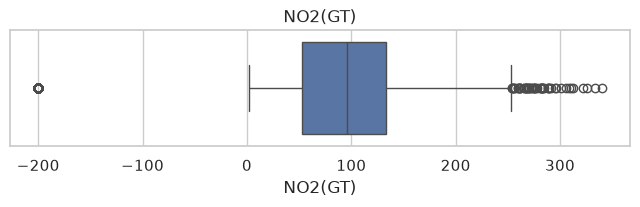

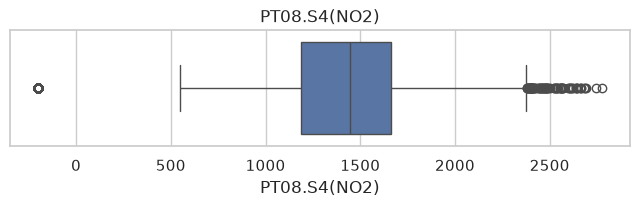

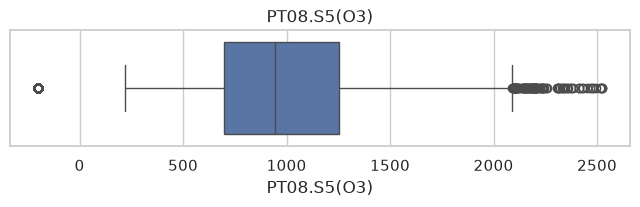

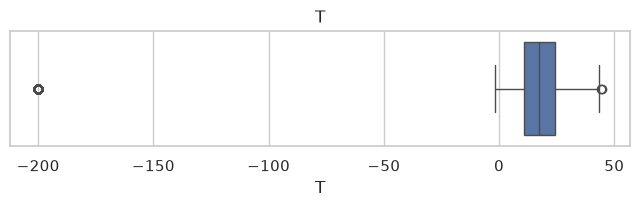

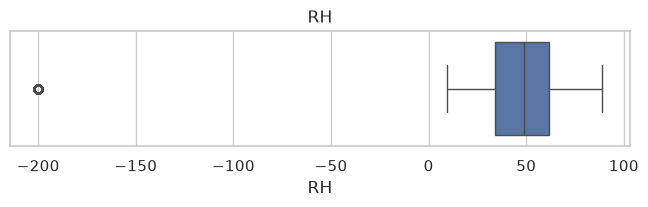

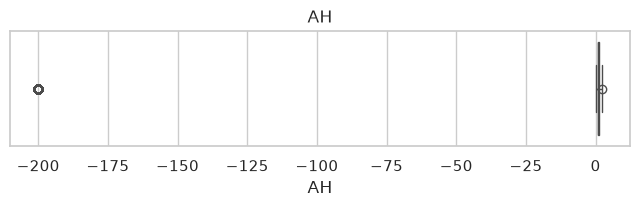

In [ ]:
# Outliers
numeric_cols = df_clean.select_dtypes(include="number").columns
for col in numeric_cols:

    plt.figure(figsize=(8, 1.5))

    sns.boxplot(
        x=df_clean[col]
    )

    plt.title(col)
    plt.show()

## 4. Missing-value strategy

This template retains missing measurements rather than imputing across the full time series. For modelling, fit imputers using **training data only** (ideally inside a scikit-learn Pipeline). Avoid interpolation that uses future observations when forecasting.

## 5. Save processed data

In [ ]:
cleaned = df_clean.copy()
print("Raw rows:", len(df))
print("Cleaned rows:", len(cleaned))
print("Remaining missing measurement cells:", int(cleaned[measurement_cols].isna().sum().sum()))

In [ ]:
processed_dir = PROJECT_ROOT / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)
parquet_path = processed_dir / "air_quality_cleaned.parquet"
csv_path = processed_dir / "air_quality_cleaned.csv"
cleaned.to_parquet(parquet_path, index=False)
cleaned.to_csv(csv_path, index=False)
print("Saved:", parquet_path)

## 6. Document your cleaning decisions

Explain the `-200` missing-value convention, timestamp parsing, duplicate/gap findings, rows removed and why, and why imputation was deferred. If you remove outliers or impute values, justify the method and prevent information from validation/test periods leaking into training.